In [20]:
import pandas as pd # manejo de tablas
from pathlib import Path # rutas de archivos y carpetas de forma
import cv2 # procesamiento de imágenes
import matplotlib.pyplot as plt # mostrar imágenes y gráficos 
import numpy as np # operaciones con matrices.

## Carga y visualización inicial de las imágenes

Las imágenes se encuentran organizadas en subcarpetas dentro de `Data`,
según su diagnóstico: carcinoma basocelular (BCC), carcinoma escamoso
(SCC) y queratosis seborreica (SK).

Se carga y visualiza una imagen de cada grupo para inspeccionar sus
características y detectar elementos que puedan afectar el procesamiento.
Las imágenes se convierten de BGR a RGB para representar correctamente
sus colores.

En esta etapa se conserva la resolución original y no se aplican filtros.

BCC: 22 imágenes
SCC: 16 imágenes
SK: 21 imágenes


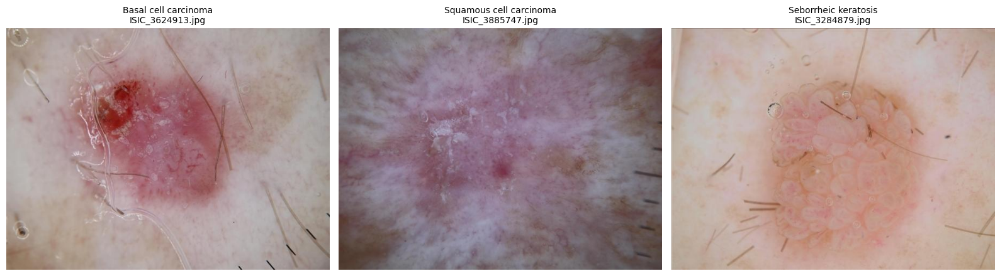

In [21]:
# Carpeta raíz donde están las imágenes. 
carpeta_data = Path("Data")

# Diccionario que asocia el nombre de cada subcarpeta (clave) con el nombre completo del diagnóstico (valor), usado en los títulos
grupos = {
    "BCC": "Basal cell carcinoma",
    "SCC": "Squamous cell carcinoma",
    "SK": "Seborrheic keratosis",
}

# Diccionario vacío donde se guardará una imagen por grupo.
# Estas tres imágenes son las que usamos en el resto del notebook
imagenes = {}

# Crear una figura
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# zip recorre en paralelo cada eje (ax) y cada par (carpeta, diagnóstico)
for ax, (carpeta, diagnostico) in zip(axes, grupos.items()):

    # Listar todos los archivos dentro de la subcarpeta (ej. Data/BCC), ordenado por nombre
    archivos = sorted(
        p for p in (carpeta_data / carpeta).rglob("*")
    )

    # Si la carpeta está vacía, se detiene la ejecución con un error
    if not archivos:
        raise FileNotFoundError(f"No hay imágenes en {carpeta}")

    # Se elige la imagen en la posición 6 si es que hay y sino la primera
    ruta = archivos[6] if len(archivos) > 1 else archivos[0]

    # Leer la imagen. OpenCV necesita la ruta como texto (str).
    # Devuelve una matriz de alto x ancho x 3 con valores de 0 a 255
    imagen = cv2.imread(str(ruta))

    # cv2.imread no da error si falla: devuelve None. Por eso se verifica
    if imagen is None:
        raise ValueError(f"No se pudo leer: {ruta}")

    # OpenCV carga los canales en orden BGR (azul, verde, rojo), pero matplotlib los interpreta como RGB. Sin esta conversión,
    # los colores se verían invertidos
    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Guardar la imagen para el preprocesamiento
    imagenes[carpeta] = imagen_rgb

    # Mostrar la imagen
    ax.imshow(imagen_rgb)
    ax.set_title(f"{diagnostico}\n{ruta.name}", fontsize=10)
    ax.axis("off")

    # Informar cuántas imágenes hay en cada grupo
    print(f"{carpeta}: {len(archivos)} imágenes")

# Ajustar los márgenes 
plt.tight_layout()
plt.show()

### Observaciones iniciales

En los ejemplos seleccionados se observan diferencias de color, contraste
y apariencia superficial. La imagen BCC presenta una región rosada de
bajo contraste respecto de la piel circundante. En la imagen SCC se
observan numerosos pelos y estructuras circulares compatibles con
burbujas. La imagen SK presenta una región de pigmentación heterogénea.
También se identifican marcas de escala en algunas imágenes.

Estos elementos pueden interferir en la segmentación y modificar las
mediciones de color y textura. Por ello, se evaluarán técnicas de
preprocesamiento procurando preservar los detalles de la lesión.

Estas observaciones corresponden únicamente a las imágenes mostradas
y no se consideran características generales de cada diagnóstico.

## Caracterización técnica del conjunto de imágenes

Se recorren todas las imágenes de las tres carpetas y se registran sus
propiedades: formato, dimensiones, cantidad de canales, tipo de dato y
profundidad de bits, además de los valores mínimo y máximo de intensidad.

El objetivo es verificar si el conjunto es homogéneo antes de procesarlo,
ya que diferencias de resolución o profundidad de bits obligarían a
normalizar las imágenes.

In [22]:
# Extensiones de archivo que se consideran imágenes
extensiones = {".jpg", ".jpeg", ".png"}

# Lista donde se acumula un diccionario por imagen
filas = []

# Recorrer cada grupo (BCC, SCC, SK)
for carpeta in grupos:
    # iterdir() lista los archivos de la carpeta (sin entrar en
    # subcarpetas); sorted los ordena alfabéticamente
    for ruta in sorted((carpeta_data / carpeta).iterdir()):

        # Saltear los archivos cuya extensión no es de imagen.
        if ruta.suffix.lower() not in extensiones:
            continue

        # IMREAD_UNCHANGED lee la imagen tal cual está guardada, sin convertirla
        imagen = cv2.imread(str(ruta), cv2.IMREAD_UNCHANGED)

        # shape devuelve (alto, ancho, canales) en imágenes color
        # o (alto, ancho) en imágenes en escala de grises.
        alto, ancho = imagen.shape[:2]

        # ndim = cantidad de dimensiones de la matriz.
        canales = 1 if imagen.ndim == 2 else imagen.shape[2]

        # Guardar las propiedades de esta imagen
        filas.append({
            "Grupo": carpeta,
            "Archivo": ruta.name,
            "Formato": ruta.suffix.lower(),
            "Ancho (px)": ancho,
            "Alto (px)": alto,
            "Canales": canales,
            "Tipo de dato": str(imagen.dtype),
            "Bits por canal": imagen.dtype.itemsize * 8,
            "Mínimo": int(imagen.min()),
            "Máximo": int(imagen.max()),
        })

# Convertir la lista de diccionarios en una tabla
caracteristicas = pd.DataFrame(filas)

print(f"Total de imágenes: {len(caracteristicas)}\n")

# Resumir la tabla por grupo
resumen = caracteristicas.groupby("Grupo").agg(
    Cantidad=("Archivo", "count"),
    Ancho=("Ancho (px)", lambda x: sorted(set(x))),
    Alto=("Alto (px)", lambda x: sorted(set(x))),
    Canales=("Canales", lambda x: sorted(set(x))),
    Bits=("Bits por canal", lambda x: sorted(set(x))),
    Formato=("Formato", lambda x: sorted(set(x))),
)
print(resumen)

Total de imágenes: 59

       Cantidad  Ancho   Alto Canales Bits Formato
Grupo                                             
BCC          22  [600]  [450]     [3]  [8]  [.jpg]
SCC          16  [600]  [450]     [3]  [8]  [.jpg]
SK           21  [600]  [450]     [3]  [8]  [.jpg]


### Resultado de la caracterización técnica

Las 59 imágenes (22 BCC, 16 SCC y 21 SK) están en formato JPEG, tienen
una resolución de 600 × 450 píxeles y tres canales de color con 8 bits
por canal (valores entre 0 y 255).

Al ser un conjunto homogéneo, no se requiere redimensionar ni normalizar
la profundidad de bits. Se debe considerar que JPEG utiliza compresión
con pérdida, que puede introducir artefactos de bloque y afectar las
mediciones de textura.

## Separación en espacios de color

Se descompone cada imagen seleccionada en sus canales RGB y HSV, y se
obtiene además su versión en escala de grises.

En RGB, cada canal representa la intensidad de rojo, verde y azul.
En HSV, el canal H representa el tono, S la saturación (pureza del color)
y V el valor o brillo. En OpenCV, H toma valores entre 0 y 179, mientras
que S y V van de 0 a 255.

El objetivo es identificar en qué canales la lesión presenta mayor
contraste respecto de la piel circundante, como criterio para elegir
la representación utilizada en la segmentación.

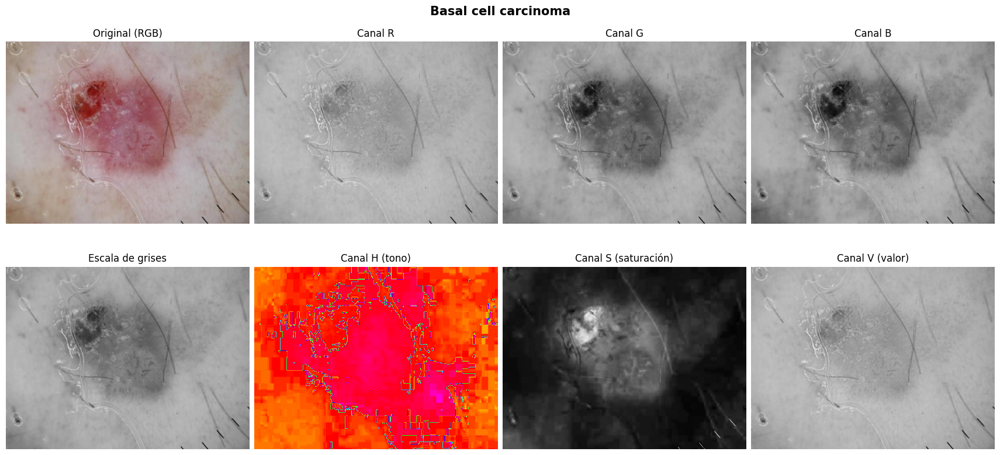

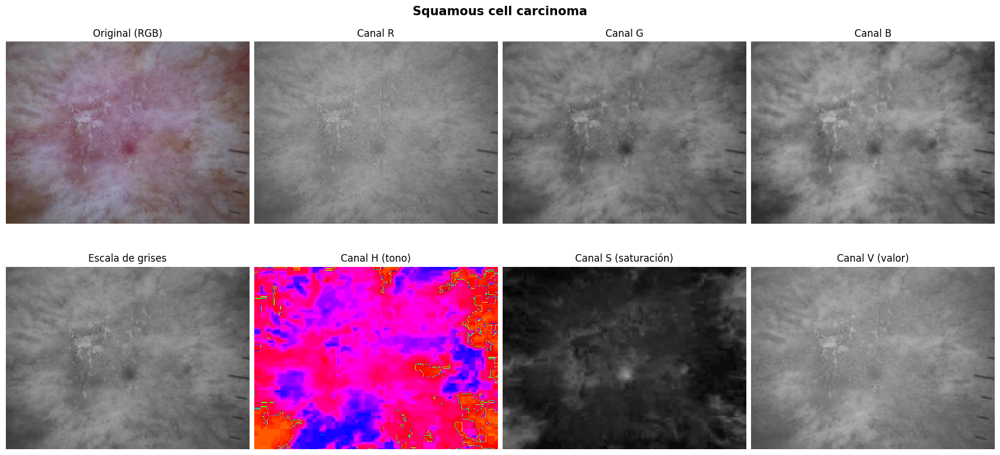

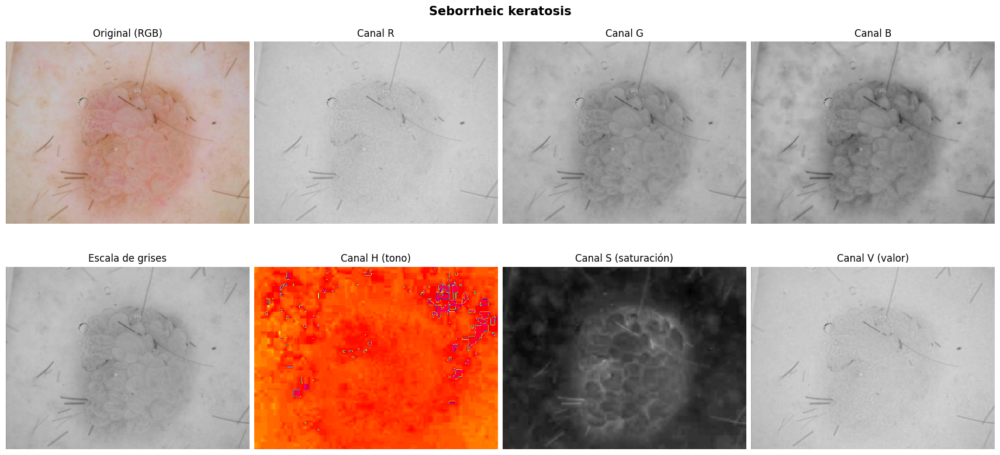

In [23]:
# Se genera una figura por cada una de las tres imágenes seleccionadas.
# "imagenes" ya contiene las imágenes en RGB 
for tipo, original in imagenes.items():

    # Convertir de RGB a HSV.
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)

    # Convertir a escala de grises 
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Lista de lo que se va a mostrar
    paneles = [
        ("Original (RGB)", original, None),
        ("Canal R", original[:, :, 0], "gray"),
        ("Canal G", original[:, :, 1], "gray"),
        ("Canal B", original[:, :, 2], "gray"),
        ("Escala de grises", gris, "gray"),
        ("Canal H (tono)", hsv[:, :, 0], "hsv"),
        ("Canal S (saturación)", hsv[:, :, 1], "gray"),
        ("Canal V (valor)", hsv[:, :, 2], "gray"),
    ]

    # Figura de 2 filas x 4 columnas = 8 paneles.    
    fig, axes = plt.subplots(
        2, 4, figsize=(17, 8), constrained_layout=True
    )

    # Título general de la figura
    fig.suptitle(grupos[tipo], fontsize=15, fontweight="bold")

    for ax, (nombre, imagen, cmap) in zip(axes.ravel(), paneles):

        if cmap is None:
            # Imagen color: se muestra directamente
            ax.imshow(imagen)

        elif cmap == "hsv":
            # El canal H se muestra con un mapa de colores circular, para ver el tono real que representa cada valor.
            # En OpenCV el tono va de 0 a 179 (no de 0 a 360)
            ax.imshow(imagen, cmap="hsv", vmin=0, vmax=179)

        else:
            # vmin y vmax fijan la escala en 0-255
            ax.imshow(imagen, cmap=cmap, vmin=0, vmax=255)

        ax.set_title(nombre)
        ax.axis("off")

    plt.show()

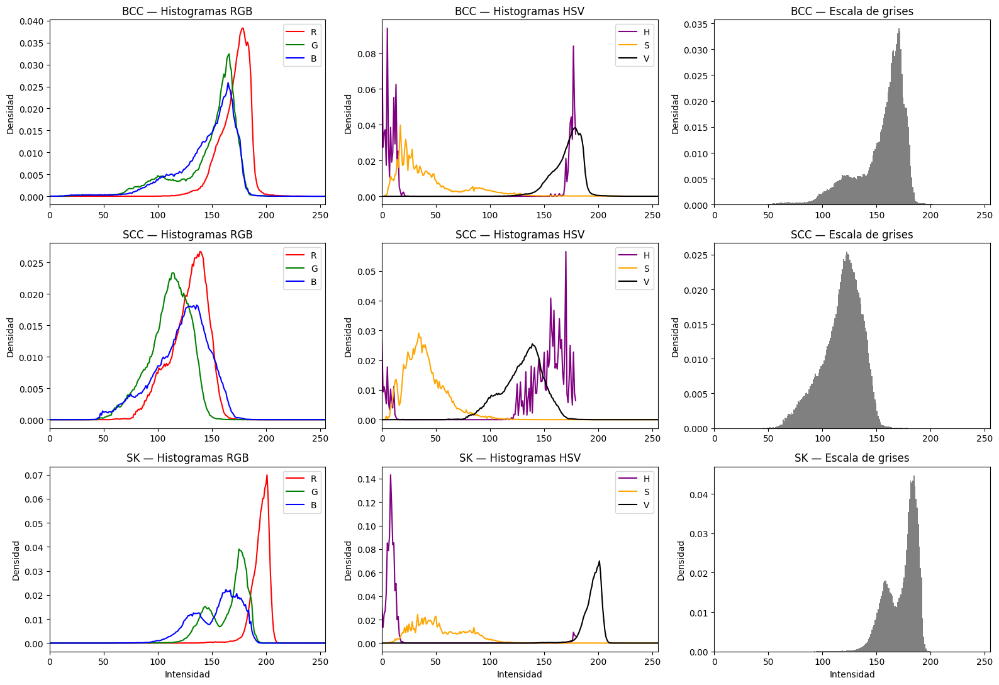

In [24]:
# Figura de 3 filas x 3 columnas
fig, axes = plt.subplots(3, 3, figsize=(16, 11))

# enumerate devuelve también el número de fila (0, 1, 2)
for fila, (tipo, original) in enumerate(imagenes.items()):
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Columna 1: histogramas RGB
    ax = axes[fila, 0]

    # Se recorre cada canal: 0 (R), 1 (G), 2 (B),y se dibuja cada uno con su color
    for i, (canal, color) in enumerate(zip("RGB", ["red", "green", "blue"])):

        # calcHist cuenta cuántos píxeles tienen cada valor de intensidad.
        hist = cv2.calcHist([original], [i], None, [256], [0, 256])

        # Se divide por el total de píxeles para obtener proporciones en lugar de cantidades. 
        # ravel() pasa el resultado de columna (256x1) a vector para poder graficarlo
        ax.plot(hist.ravel() / hist.sum(), color=color, label=canal)

    ax.set_xlim(0, 255)
    ax.set_title(f"{tipo} — Histogramas RGB")
    ax.legend()

    # Columna 2: histogramas HSV
    ax = axes[fila, 1]

    # Igual que antes
    for i, (canal, color, maximo) in enumerate(
        zip(["H", "S", "V"], ["purple", "orange", "black"], [180, 256, 256])
    ):
        hist = cv2.calcHist([hsv], [i], None, [maximo], [0, maximo])
        ax.plot(hist.ravel() / hist.sum(), color=color, label=canal)

    ax.set_xlim(0, 255)
    ax.set_title(f"{tipo} — Histogramas HSV")
    ax.legend()

    # Columna 3: histograma en escala de grises
    ax = axes[fila, 2]
    ax.hist(gris.ravel(), bins=256, range=(0, 256),
            density=True, color="gray")
    ax.set_xlim(0, 255)
    ax.set_title(f"{tipo} — Escala de grises")

    for ax in axes[fila]:
        ax.set_ylabel("Densidad")

for ax in axes[2]:
    ax.set_xlabel("Intensidad")

plt.tight_layout()
plt.show()

In [25]:
# Lista donde se acumula una fila por cada combinación imagen-canal
filas = []

for tipo, original in imagenes.items():
    hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Diccionario con los canales a analizar: nombre -> matriz 2D.
    canales = {
        "R": original[:, :, 0], "G": original[:, :, 1],
        "B": original[:, :, 2], "S": hsv[:, :, 1],
        "V": hsv[:, :, 2], "Gris": gris,
    }

    for nombre, canal in canales.items():
        filas.append({
            "Grupo": tipo,
            "Canal": nombre,
            "Media": canal.mean(),
            "Desvío": canal.std(),
            "Mínimo": int(canal.min()),
            "Máximo": int(canal.max()),
        })

estadisticas_canales = pd.DataFrame(filas)

# pivot reorganiza la tabla: una fila por canal y una columna por grupo
print(
    estadisticas_canales
    .pivot(index="Canal", columns="Grupo", values=["Media", "Desvío"])
    .round(1)
    .reindex(["R", "G", "B", "S", "V", "Gris"])
)

       Media               Desvío            
Grupo    BCC    SCC     SK    BCC   SCC    SK
Canal                                        
R      171.3  128.4  195.0   13.7  17.4   8.1
G      146.5  110.6  165.3   28.9  18.8  17.3
B      145.2  121.8  154.7   27.4  25.2  21.4
S       43.6   39.7   53.2   33.4  18.8  23.9
V      171.3  130.0  195.0   13.7  18.8   8.1
Gris   153.8  117.2  173.0   23.5  18.5  14.2


### Observaciones sobre los canales de color

En las tres imágenes, el canal R presenta valores altos y poco
contraste entre la lesión y la piel (desvío entre 8 y 17), ya que ambas
tienen un componente rojo importante. En BCC y SK, los canales G y B
muestran mayor variabilidad y la lesión se distingue con más claridad,
por lo que resultan más útiles para separarla del fondo. En SCC, la
lesión presenta bajo contraste en todos los canales.

El canal V coincide prácticamente con R, porque V toma el máximo de los
tres canales y en la piel ese máximo suele ser el rojo. En la imagen BCC,
el canal S resalta la región más pigmentada de la lesión.

En BCC y SK, el canal H se concentra cerca de 0 y de 179, ambos extremos
correspondientes a tonos rojizos; en SCC aparecen además tonos violáceos
y azulados. Por ser un ángulo, no se calcula su media, que no sería
representativa. Además, en las zonas de baja saturación (pelos, burbujas
y reflejos blanquecinos) el tono queda indefinido y aparecen valores
dispersos, por lo que H resulta poco confiable en esas regiones.

En escala de grises, el histograma de SK es bimodal, lo que sugiere dos
poblaciones (lesión y piel) separables por un umbral. En SCC el
histograma es unimodal, lo que complicará su segmentación por
umbralización.

Estas observaciones corresponden a una imagen por grupo y no se
generalizan a cada diagnóstico.

## Preprocesamiento: comparación de filtros de suavizado

Se comparan un filtro de mediana y un filtro gaussiano, utilizando
ventanas de 3 × 3 píxeles.

El filtro de mediana reemplaza cada valor por la mediana de su entorno.
El filtro gaussiano realiza un promedio ponderado, asignando mayor peso
a los píxeles cercanos al centro de la ventana.

Se aplica cada filtro de manera independiente sobre la imagen original.
Se evalúa visualmente su efecto sobre los bordes y los detalles de la
lesión. No se asume que las imágenes presentan ruido de un tipo específico
ni que el suavizado mejora necesariamente su calidad.

Estos filtros no constituyen un método específico de eliminación de pelos.

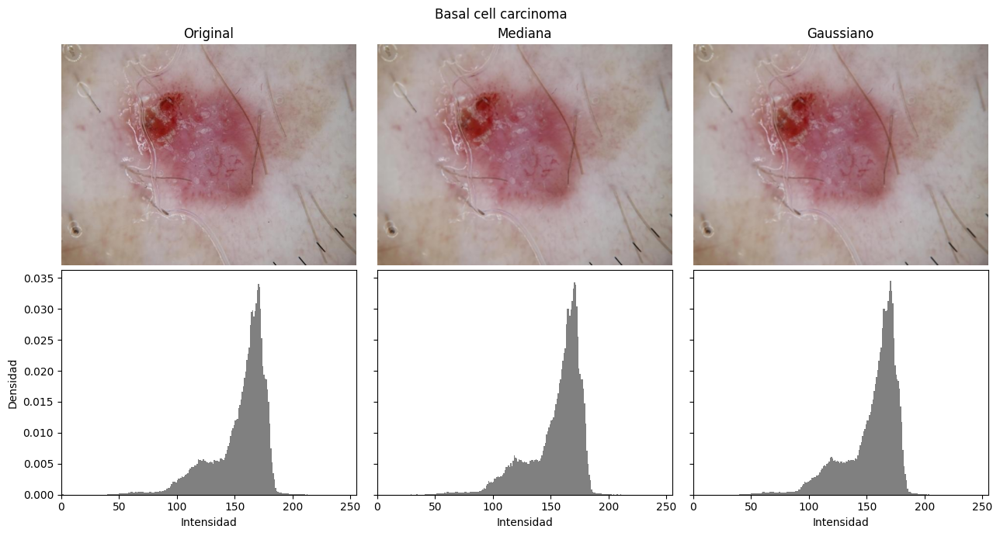

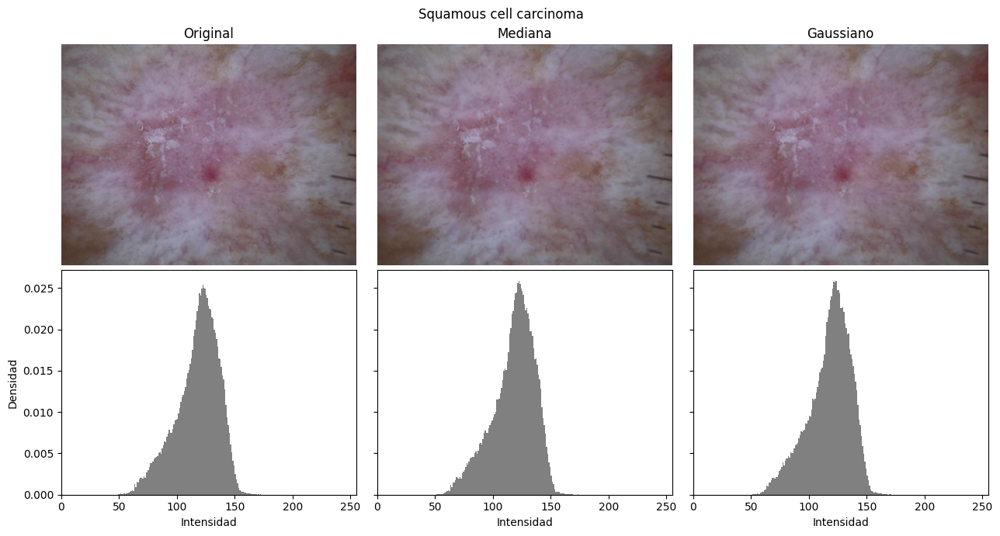

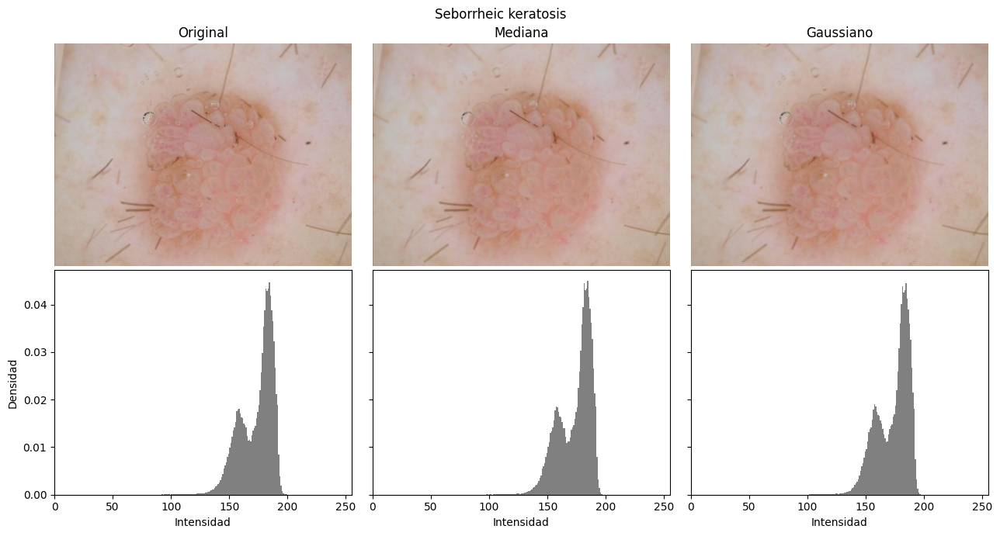

In [26]:
# Se recorre cada una de las tres imágenes seleccionadas.
# tipo = "BCC", "SCC" o "SK"; original = la imagen RGB correspondiente
for tipo, original in imagenes.items():

    # Diccionario con las tres versiones a comparar
    variantes = {
        "Original": original,
        "Mediana": cv2.medianBlur(original, 3),
        "Gaussiano": cv2.GaussianBlur(original, (3, 3), 1),
    }

    # Figura de 2 filas x 3 columnas
    fig, axes = plt.subplots(
        2, 3, figsize=(13, 7),
        sharex="row", sharey="row"
    )
    fig.suptitle(grupos[tipo])
    
    for columna, (nombre, imagen) in enumerate(variantes.items()):
        # Mostrar imagen
        axes[0, columna].imshow(imagen)
        axes[0, columna].set_title(nombre)
        axes[0, columna].axis("off")

        # Mostrar histograma en escala de grises
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

        axes[1, columna].hist(
            gris.ravel(),
            bins=256,
            range=(0, 256),
            density=True,
            color="gray"
        )
        axes[1, columna].set_xlabel("Intensidad")
        axes[1, columna].set_xlim(0, 255)

    axes[1, 0].set_ylabel("Densidad")

    plt.tight_layout()
    plt.show()

### Resultado de la comparación

En el ejemplo de carcinoma basocelular, los filtros de mediana y
gaussiano con ventanas de 3 × 3 producen cambios visuales sutiles.
Los histogramas mantienen una distribución similar a la original.

La similitud entre histogramas no implica que se conserven todos los
detalles espaciales. Por ello, se requiere inspeccionar regiones ampliadas
y evaluar posteriormente el efecto sobre la segmentación.

Los pelos y las marcas de escala permanecen visibles tras el filtrado.

### Inspección ampliada y comparación cuantitativa del suavizado

Para evaluar el efecto de los filtros sobre los detalles finos, se
amplía un recorte central de 150 × 150 píxeles de cada imagen. Se
agregan además ventanas de 5 × 5 para observar cómo varía el efecto
al aumentar el tamaño del filtro.

Para la comparación cuantitativa se calculan, sobre la imagen en escala
de grises, indicadores asociados a la calidad de una imagen:

- **Brillo:** media de intensidad.
- **Contraste:** desvío estándar de la intensidad.
- **Nitidez:** magnitud media del gradiente calculado con el operador
  de Sobel, que es alta en bordes y detalles finos.
- **PSNR** (relación señal a ruido pico) respecto de la original: indica
  cuánto se modificó la imagen. Valores más altos implican mayor
  similitud con la original. Al no disponer de una imagen libre de ruido como referencia, el PSNR no
  mide la calidad absoluta, sino el grado de modificación introducido
  por cada filtro.

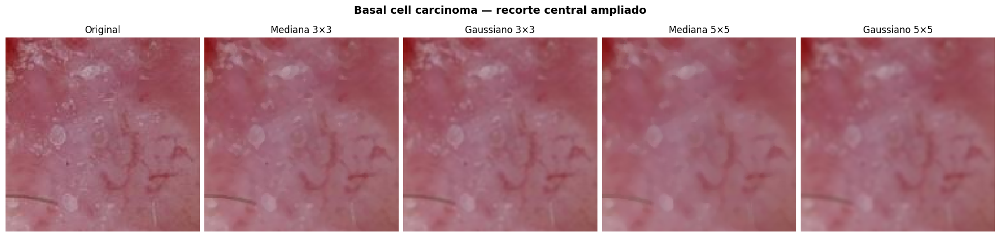

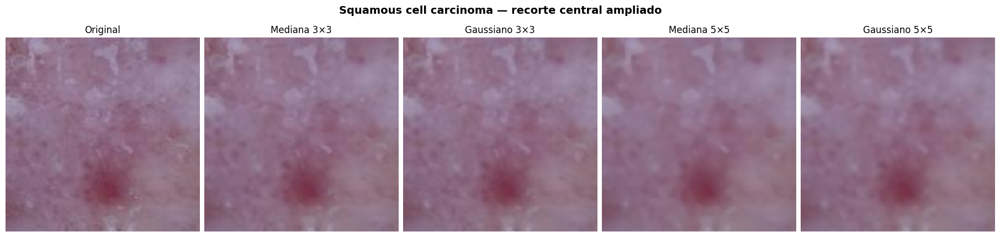

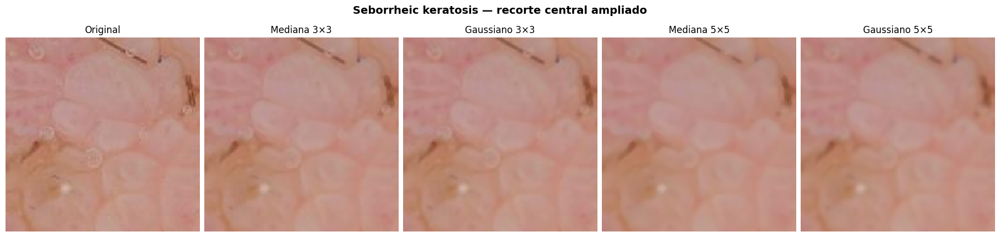

In [27]:
# Tamaño del recorte cuadrado, en píxeles
lado = 150

for tipo, original in imagenes.items():

    # Dimensiones de la imagen (alto = filas, ancho = columnas)
    alto, ancho = original.shape[:2]

    # Esquina superior izquierda del recorte, calculada para que quede
    # centrado en la imagen, donde suele estar la lesión.
    y0 = alto // 2 - lado // 2
    x0 = ancho // 2 - lado // 2

    # Se agregan ventanas de 5x5 para observar cómo cambia el efecto al aumentar el tamaño del filtro. 
    variantes = {
        "Original": original,
        "Mediana 3×3": cv2.medianBlur(original, 3),
        "Gaussiano 3×3": cv2.GaussianBlur(original, (3, 3), 1),
        "Mediana 5×5": cv2.medianBlur(original, 5),
        "Gaussiano 5×5": cv2.GaussianBlur(original, (5, 5), 1.5),
    }

    # Una fila de 5 paneles
    fig, axes = plt.subplots(
        1, 5, figsize=(18, 4.5), constrained_layout=True
    )
    fig.suptitle(
        f"{grupos[tipo]} — recorte central ampliado",
        fontsize=14, fontweight="bold"
    )

    for ax, (nombre, imagen) in zip(axes, variantes.items()):

        # Se muestra solo el recorte
        ax.imshow(
            imagen[y0:y0 + lado, x0:x0 + lado],
            interpolation="nearest"
        )
        ax.set_title(nombre)
        ax.axis("off")

    plt.show()

In [28]:
def metricas_calidad(gris, referencia):
    """
    Calcula indicadores de calidad sobre una imagen en escala de grises.
    gris: imagen a evaluar
    referencia: imagen original en grises, para calcular el PSNR
    Devuelve un diccionario con los valores.
    """

    # Gradiente con el operador de Sobel
    gx = cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3) # ksize=3 es el tamaño del kernel
    gy = cv2.Sobel(gris, cv2.CV_64F, 0, 1, ksize=3)

    # Magnitud del gradiente en cada píxel: es alta en bordes y detalles finos, y baja en zonas uniformes.
    # Su promedio se usa como medida de nitidez
    magnitud = np.sqrt(gx**2 + gy**2)

    # PSNR (relación señal a ruido pico) compara la imagen con la
    # original: cuanto MAYOR, MÁS PARECIDA. Si son idénticas, el
    # PSNR es infinito, por eso en ese caso se deja vacío (NaN)
    if np.array_equal(gris, referencia):
        psnr = np.nan
    else:
        psnr = cv2.PSNR(referencia, gris)

    return {
        "Brillo (media)": gris.mean(),
        "Contraste (desvío)": gris.std(),
        "Nitidez (gradiente medio)": magnitud.mean(),
        "PSNR vs original (dB)": psnr,
    }


# Lista donde se acumula una fila por cada combinación imagen-filtro
filas = []

for tipo, original in imagenes.items():

    # Mismas variantes que en la figura ampliada
    variantes = {
        "Original": original,
        "Mediana 3×3": cv2.medianBlur(original, 3),
        "Gaussiano 3×3": cv2.GaussianBlur(original, (3, 3), 1),
        "Mediana 5×5": cv2.medianBlur(original, 5),
        "Gaussiano 5×5": cv2.GaussianBlur(original, (5, 5), 1.5),
    }

    # La original en grises es la referencia para el PSNR
    gris_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    for nombre, imagen in variantes.items():
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

        # agrega al diccionario todas las métricas devueltas por la función, junto con el grupo y el nombre del filtro
        filas.append({
            "Grupo": tipo,
            "Filtro": nombre,
            **metricas_calidad(gris, gris_original),
        })

metricas_suavizado = pd.DataFrame(filas)

# Mostrar la tabla redondeada a 2 decimales, sin la columna de índice
print(metricas_suavizado.round(2).to_string(index=False))

Grupo        Filtro  Brillo (media)  Contraste (desvío)  Nitidez (gradiente medio)  PSNR vs original (dB)
  BCC      Original          153.80               23.53                      19.48                    NaN
  BCC   Mediana 3×3          153.78               23.27                      15.62                  41.56
  BCC Gaussiano 3×3          153.79               23.21                      15.69                  41.72
  BCC   Mediana 5×5          153.79               22.96                      11.74                  36.55
  BCC Gaussiano 5×5          153.79               22.98                      12.72                  37.60
  SCC      Original          117.21               18.55                      17.61                    NaN
  SCC   Mediana 3×3          117.24               18.43                      14.44                  46.17
  SCC Gaussiano 3×3          117.21               18.41                      14.59                  46.86
  SCC   Mediana 5×5          117.28           

### Resultado de la comparación cuantitativa

En las tres imágenes, ningún filtro modifica de forma apreciable el
brillo (la media varía menos de 0,1 niveles de gris) y el contraste
global disminuye menos de un 4 %. Esto es coherente con la similitud
de los histogramas observada previamente.

La nitidez, en cambio, se reduce entre un 16 % y un 20 % con las
ventanas de 3 × 3, y entre un 32 % y un 40 % con las de 5 × 5. Los
filtros atenúan los detalles finos aunque el histograma no cambie.

En los recortes ampliados se observa que las ventanas de 5 × 5 difuminan
estructuras propias de la lesión, como los vasos de la imagen BCC y los
contornos de los glóbulos de la imagen SK, mientras que los pelos más
gruesos permanecen visibles. Las diferencias entre mediana y gaussiano
del mismo tamaño son pequeñas.

Dado que el suavizado no elimina los artefactos principales y reduce
detalles que pueden ser relevantes para el análisis de textura, se
opta por no aumentar el tamaño de la ventana. La corrección de pelos
se aborda con un método específico en las secciones siguientes.

## Pruebas de mejora de contraste

Se comparan dos métodos de mejora de contraste: ecualización global del
histograma y ecualización adaptativa con limitación de contraste (CLAHE).

Ambos métodos se aplican sobre las versiones en escala de grises de las
tres imágenes seleccionadas, utilizando los mismos parámetros para todos
los diagnósticos. Se visualizan los resultados y sus histogramas para
evaluar los cambios en la distribución de intensidades y el realce de
detalles y artefactos.

El objetivo es identificar una alternativa que facilite la segmentación
posterior, procurando preservar las características relevantes de las
lesiones.

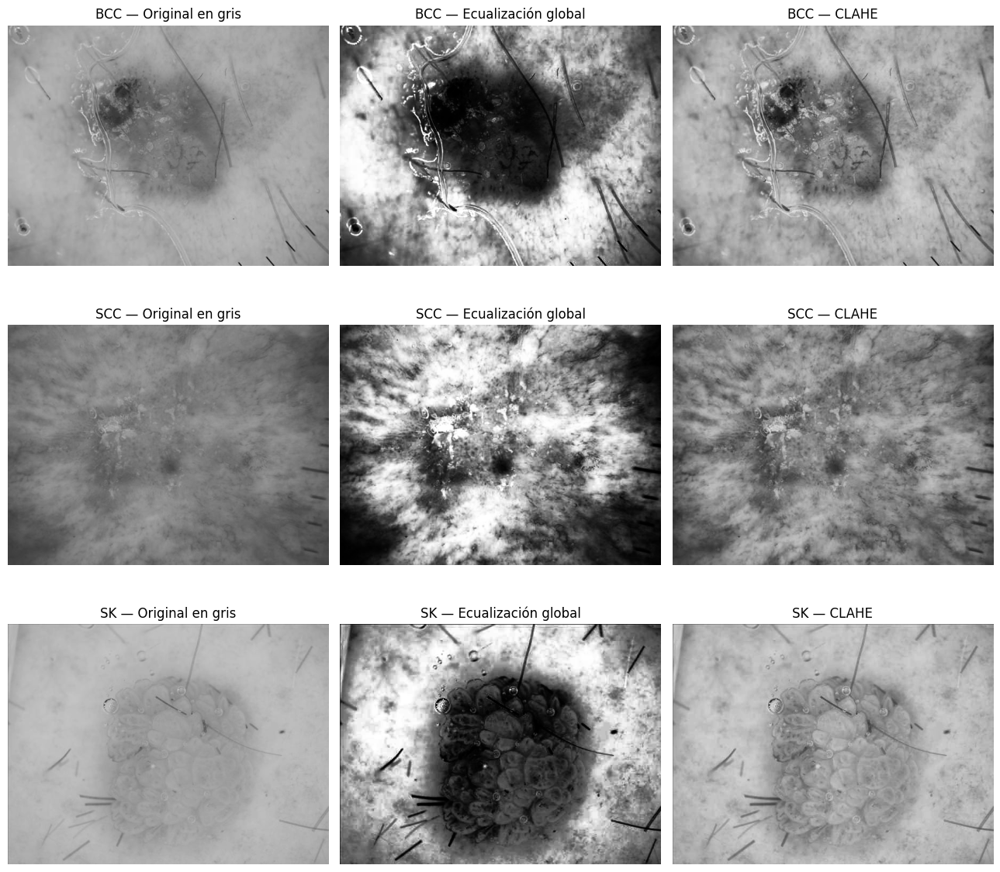

In [29]:
contraste = {}

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    variantes = {
        "Original en gris": gris,
        "Ecualización global": cv2.equalizeHist(gris),
        "CLAHE": clahe.apply(gris),
    }

    contraste[tipo] = variantes

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        axes[fila, columna].imshow(
            imagen, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(f"{tipo} — {nombre}")
        axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

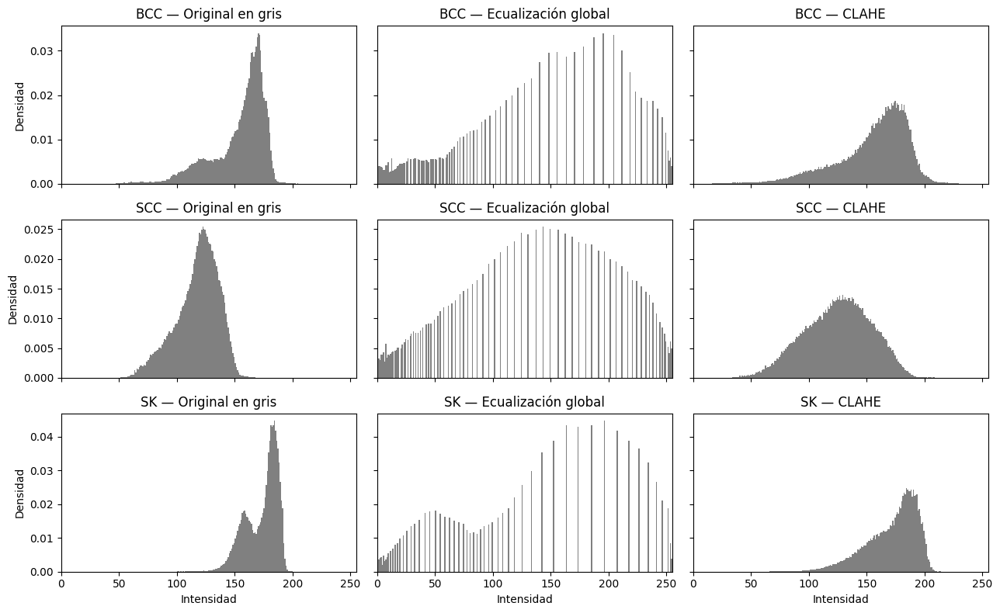

In [30]:
fig, axes = plt.subplots(
    3, 3, figsize=(13, 8),
    sharex=True, sharey="row"
)

for fila, (tipo, variantes) in enumerate(contraste.items()):
    for columna, (nombre, imagen) in enumerate(variantes.items()):
        ax = axes[fila, columna]

        ax.hist(
            imagen.ravel(), bins=256,
            range=(0, 256), density=True, color="gray"
        )
        ax.set_title(f"{tipo} — {nombre}")
        ax.set_xlim(0, 255)

        if fila == 2:
            ax.set_xlabel("Intensidad")
        if columna == 0:
            ax.set_ylabel("Densidad")

plt.tight_layout()
plt.show()

### Comparación de los métodos de mejora de contraste

En los tres ejemplos, la ecualización global amplía el rango de
intensidades y produce un aumento pronunciado del contraste. Sin embargo,
también realza estructuras de la piel circundante y artefactos que podrían
interferir en la segmentación.

CLAHE produce un realce visual más moderado con los parámetros utilizados.
Por ello, se selecciona como alternativa preliminar para continuar el
desarrollo del pipeline, manteniendo los mismos parámetros para los tres
diagnósticos.

Esta selección deberá validarse mediante la segmentación y su evaluación
sobre más imágenes. La ampliación del histograma, por sí sola, no demuestra
una mejora en la delimitación de las lesiones.

## Detección de posibles pelos y artefactos oscuros

Se aplica la transformación morfológica black-hat, calculada como la
diferencia entre el cierre de la imagen y la imagen original. Esta
operación resalta estructuras oscuras menores que el elemento
estructurante utilizado.

La respuesta se umbraliza para obtener una máscara de posibles
artefactos. Se utilizan los mismos parámetros para las tres imágenes.

Se inspecciona la máscara antes de corregir los píxeles detectados,
ya que también pueden incluirse marcas de escala y estructuras propias
de la lesión.

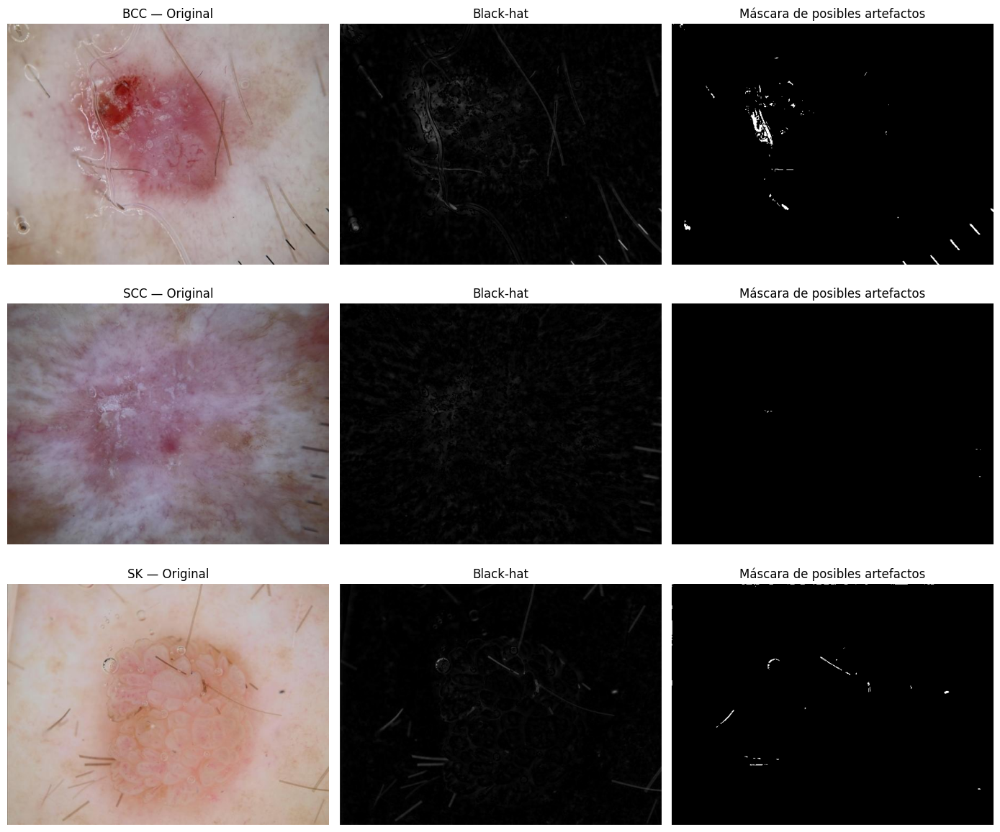

In [31]:
mascaras_artefactos = {}

# Parámetros iniciales de prueba, iguales para las tres imágenes
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))
umbral = 50

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Resaltar estructuras oscuras pequeñas o delgadas
    blackhat = cv2.morphologyEx(
        gris, cv2.MORPH_BLACKHAT, kernel
    )

    # Máscara: blanco = posible artefacto
    _, mascara = cv2.threshold(
        blackhat, umbral, 255, cv2.THRESH_BINARY
    )

    mascaras_artefactos[tipo] = mascara

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(blackhat, cmap="gray", vmin=0, vmax=255)
    axes[fila, 1].set_title("Black-hat")

    axes[fila, 2].imshow(mascara, cmap="gray", vmin=0, vmax=255)
    axes[fila, 2].set_title("Máscara de posibles artefactos")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Refinamiento de las máscaras de posibles artefactos

Se utiliza inicialmente un umbral de 70 para reducir la inclusión de
estructuras de la lesión. Se comparan operaciones de cierre y apertura
con un elemento estructurante elíptico de 3 × 3 píxeles.

El cierre busca unir pequeñas discontinuidades, mientras que la apertura
permite eliminar componentes pequeños, aunque también puede suprimir
pelos finos. Se inspeccionan ambos resultados antes de seleccionar
el refinamiento y aplicar la corrección de artefactos.

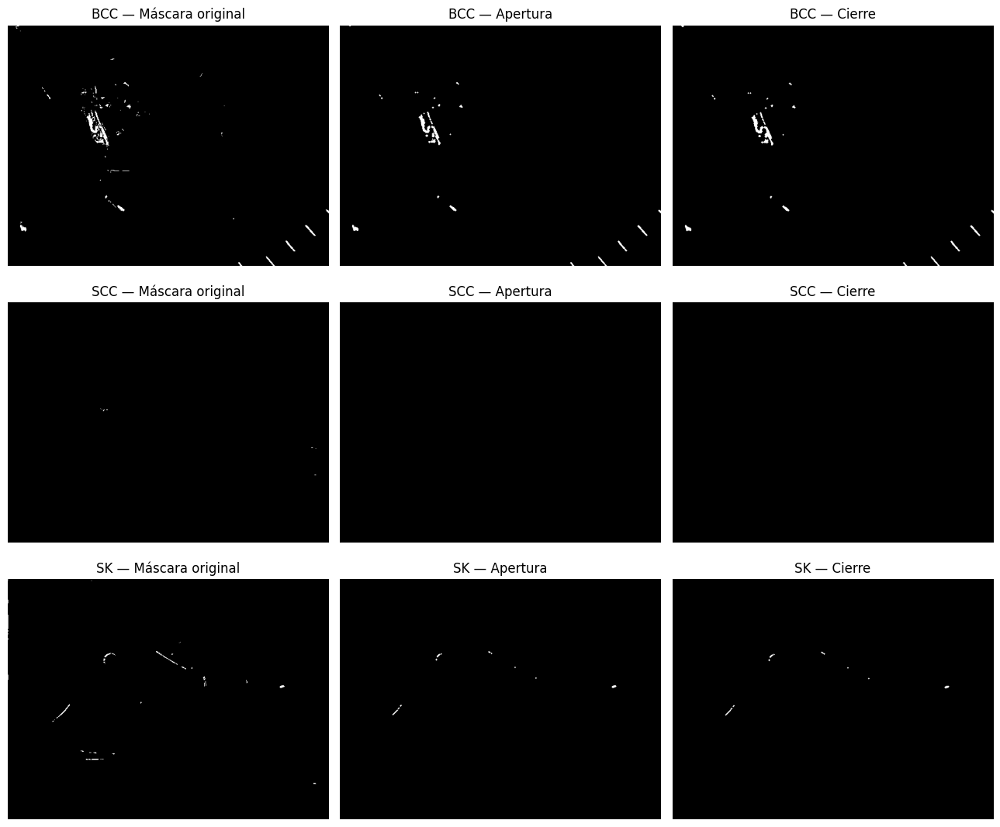

In [32]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

fig, axes = plt.subplots(3, 3, figsize=(13, 11))

for fila, (tipo, mascara) in enumerate(mascaras_artefactos.items()):

    apertura = cv2.morphologyEx(
            mascara, cv2.MORPH_OPEN, kernel
        )
    
    cierre = cv2.morphologyEx(
        apertura, cv2.MORPH_CLOSE, kernel
    )

    variantes = {
        "Máscara original": mascara,
        "Apertura": apertura,
        "Cierre": cierre,
    }

    for columna, (nombre, resultado) in enumerate(variantes.items()):
        axes[fila, columna].imshow(
            resultado, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(f"{tipo} — {nombre}")
        axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

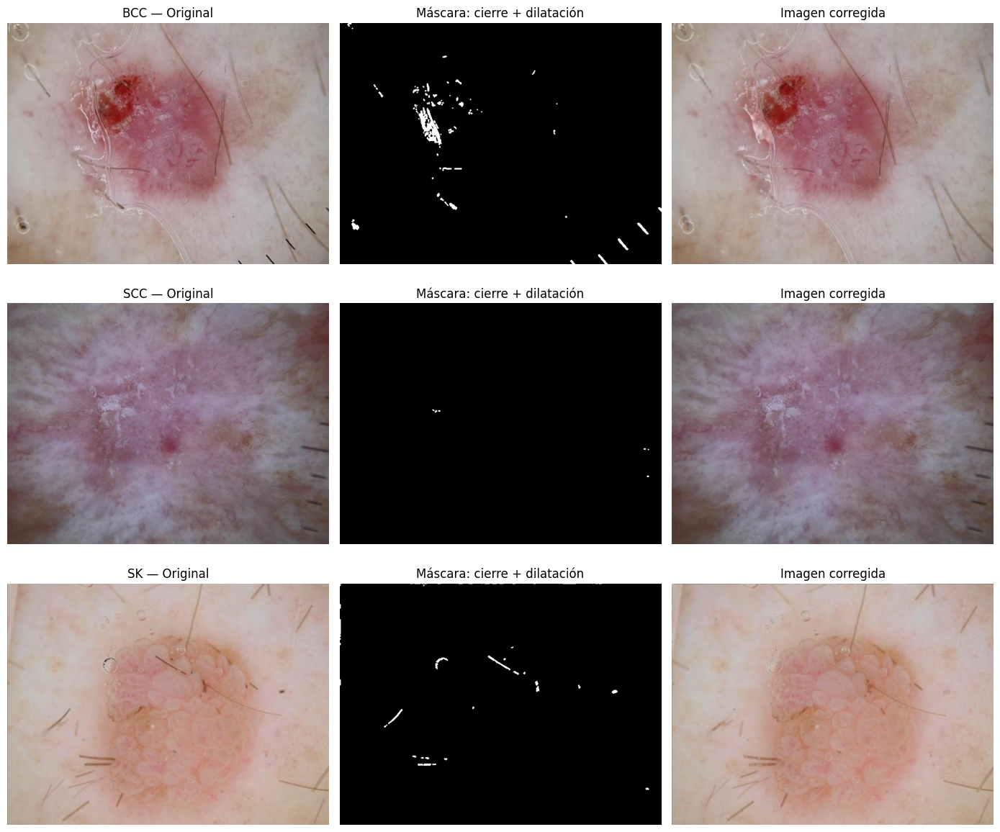

In [33]:
imagenes_corregidas = {}
mascaras_refinadas = {}

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_artefactos[tipo]

    # Unir pequeñas discontinuidades sin eliminar líneas finas
    cierre = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel
    )

    # Ampliar ligeramente la cobertura de los artefactos detectados
    refinada = cv2.dilate(cierre, kernel, iterations=1)

    # Corregir únicamente los píxeles blancos de la máscara
    corregida = cv2.inpaint(
        original, refinada, 3, cv2.INPAINT_TELEA
    )

    mascaras_refinadas[tipo] = refinada
    imagenes_corregidas[tipo] = corregida

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(refinada, cmap="gray", vmin=0, vmax=255)
    axes[fila, 1].set_title("Máscara: cierre + dilatación")

    axes[fila, 2].imshow(corregida)
    axes[fila, 2].set_title("Imagen corregida")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Resultado de la corrección de artefactos

El cierre seguido de dilatación conserva más estructuras delgadas que
la apertura seguida de cierre. Su aplicación junto con inpainting
atenúa parcialmente pelos y marcas de escala.

Sin embargo, permanecen artefactos sin corregir y se detectan regiones
dentro de la lesión que podrían corresponder a estructuras propias.
Por lo tanto, esta configuración se considera preliminar y no se
asume que preserve todas las características de color y textura.

## Primera prueba de segmentación: efecto de la corrección de artefactos

Se comparan dos alternativas: imagen original e imagen corregida mediante
inpainting. Ambas se convierten a escala de grises y se procesan con
CLAHE utilizando los mismos parámetros.

Luego se aplica Otsu, que determina automáticamente un umbral para cada
imagen. Se utiliza umbralización inversa para representar en blanco las
regiones oscuras consideradas candidatas a lesión.

Esta es una prueba inicial: las regiones oscuras también pueden incluir
pelos, marcas o piel circundante. Se comparan las máscaras y sus contornos
sobre la imagen original para evaluar visualmente sus limitaciones.

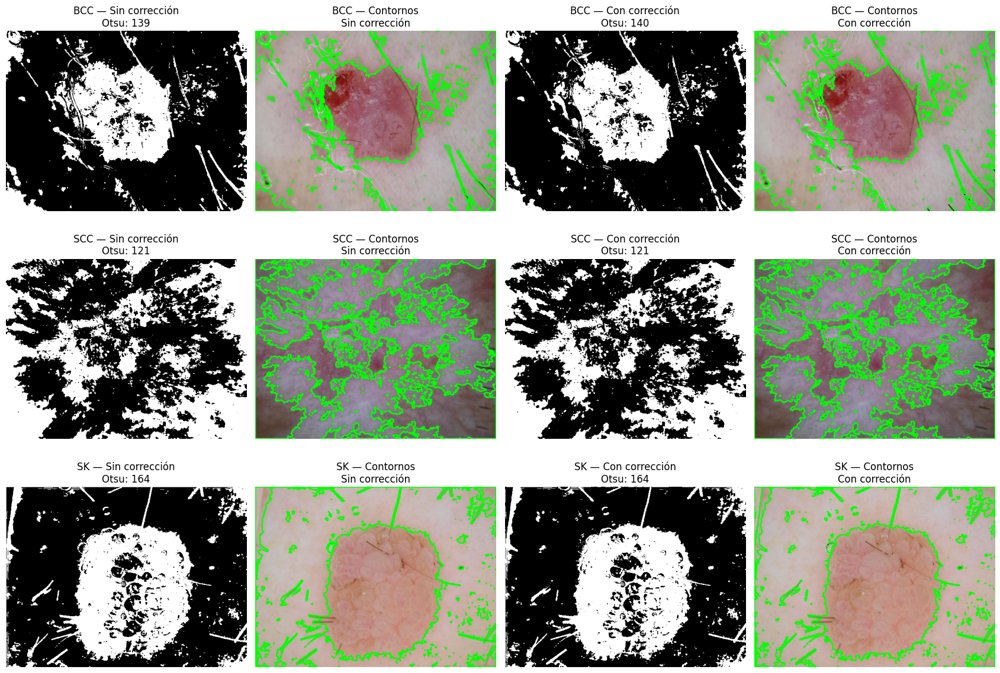

In [34]:
mascaras_otsu = {}

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

fig, axes = plt.subplots(3, 4, figsize=(17, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):

    variantes = {
        "Sin corrección": original,
        "Con corrección": imagenes_corregidas[tipo],
    }

    mascaras_otsu[tipo] = {}

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
        mejorada = clahe.apply(gris)

        umbral, mascara = cv2.threshold(
            mejorada, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        mascaras_otsu[tipo][nombre] = mascara

        # Mostrar máscara
        axes[fila, 2 * columna].imshow(
            mascara, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, 2 * columna].set_title(
            f"{tipo} — {nombre}\nOtsu: {umbral:.0f}"
        )

        # Mostrar contornos sobre la original
        contornos, _ = cv2.findContours(
            mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        superpuesta = original.copy()
        cv2.drawContours(
            superpuesta, contornos, -1, (0, 255, 0), 2
        )

        axes[fila, 2 * columna + 1].imshow(superpuesta)
        axes[fila, 2 * columna + 1].set_title(
            f"{tipo} — Contornos\n{nombre}"
        )

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Segmentación mediante GrabCut

La segmentación mediante Otsu presentó regiones fragmentadas y dificultades
para separar la lesión de la piel circundante. Por ello, se evaluó GrabCut
como método alternativo, que utiliza información de color y relaciones
entre píxeles vecinos para separar primer plano y fondo.

Se definió un rectángulo inicial excluyendo un margen del 5 % de la imagen,
considerado fondo, y se aplicaron cinco iteraciones. Se utilizaron los
mismos parámetros para los tres diagnósticos.

Las máscaras obtenidas presentaron regiones más continuas que las de Otsu,
aunque persistió la inclusión de piel circundante y algunos artefactos.
Como refinamiento, se conservó el componente conectado de mayor área,
suponiendo que corresponde a la lesión principal, para eliminar pequeñas
regiones aisladas.

Finalmente, se visualizaron los contornos sobre las imágenes originales
para inspeccionar la delimitación. Esta comparación es cualitativa y no
demuestra por sí sola una mayor precisión de segmentación.

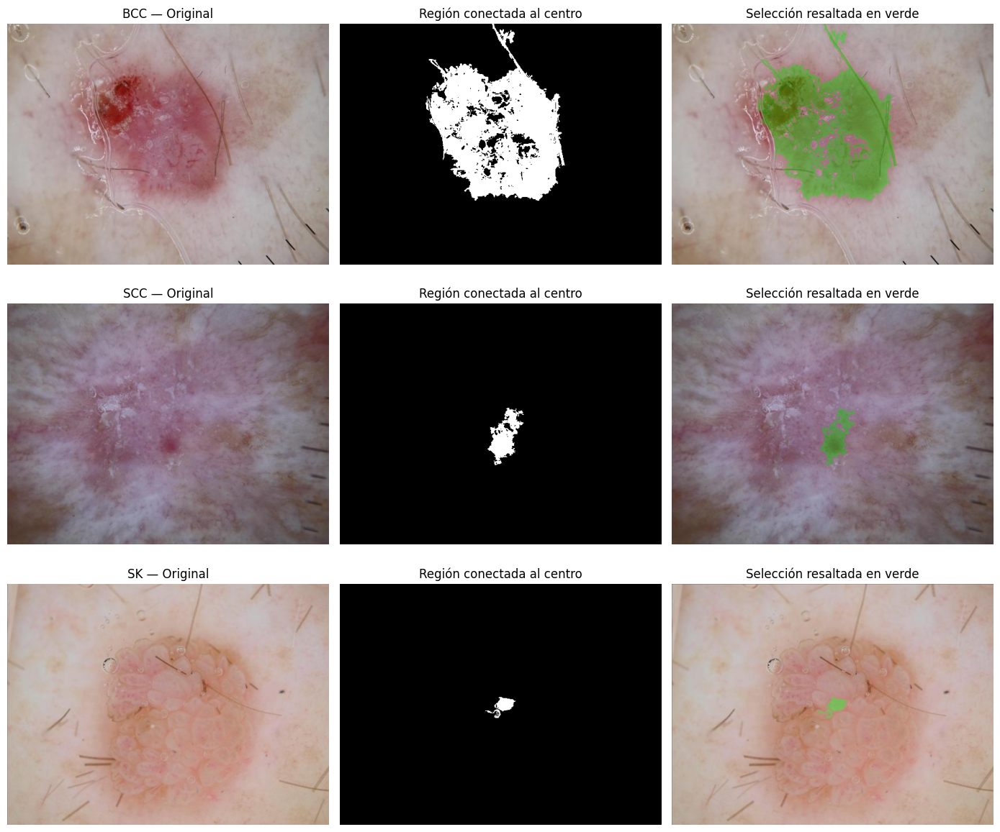

In [35]:
mascaras_lesion = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_otsu[tipo]["Con corrección"]
    alto, ancho = mascara.shape

    # Considerar candidata la clase presente en el centro:
    # puede ser blanca o negra en la máscara de Otsu
    valor_central = mascara[alto // 2, ancho // 2]
    candidata = (mascara == valor_central).astype("uint8")

    # Conservar solamente la región conectada al centro
    _, etiquetas = cv2.connectedComponents(candidata, connectivity=8)
    etiqueta_central = etiquetas[alto // 2, ancho // 2]

    seleccion = (
        (etiquetas == etiqueta_central).astype("uint8") * 255
    )

    mascaras_lesion[tipo] = seleccion

    # Resaltar los píxeles seleccionados sobre la original
    superpuesta = original.copy()
    dentro = seleccion > 0
    superpuesta[dentro] = (
        0.65 * original[dentro] + 0.35 * np.array([0, 255, 0])
    ).astype("uint8")

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        seleccion, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Región conectada al centro")

    axes[fila, 2].imshow(superpuesta)
    axes[fila, 2].set_title("Selección resaltada en verde")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

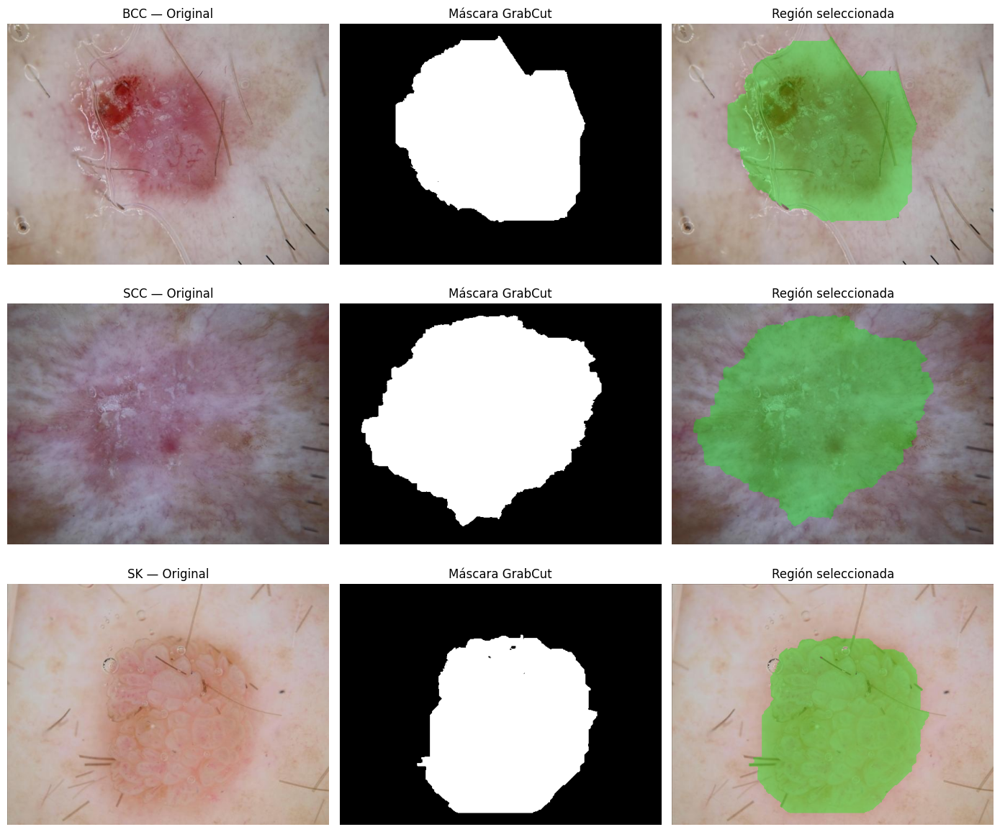

In [36]:
mascaras_grabcut = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    alto, ancho = original.shape[:2]

    # Rectángulo inicial: excluye un margen del 5 %
    mx = max(1, int(ancho * 0.05))
    my = max(1, int(alto * 0.05))
    rectangulo = (mx, my, ancho - 2 * mx, alto - 2 * my)

    etiquetas = np.zeros((alto, ancho), dtype=np.uint8)
    modelo_fondo = np.zeros((1, 65), dtype=np.float64)
    modelo_lesion = np.zeros((1, 65), dtype=np.float64)

    cv2.setRNGSeed(42)
    cv2.grabCut(
        original, etiquetas, rectangulo,
        modelo_fondo, modelo_lesion,
        5, cv2.GC_INIT_WITH_RECT
    )

    # Primer plano seguro o probable
    mascara = np.where(
        (etiquetas == cv2.GC_FGD) |
        (etiquetas == cv2.GC_PR_FGD),
        255, 0
    ).astype("uint8")

    mascaras_grabcut[tipo] = mascara

    superpuesta = original.copy()
    dentro = mascara > 0
    superpuesta[dentro] = (
        0.65 * original[dentro] +
        0.35 * np.array([0, 255, 0])
    ).astype("uint8")

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        mascara, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Máscara GrabCut")

    axes[fila, 2].imshow(superpuesta)
    axes[fila, 2].set_title("Región seleccionada")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

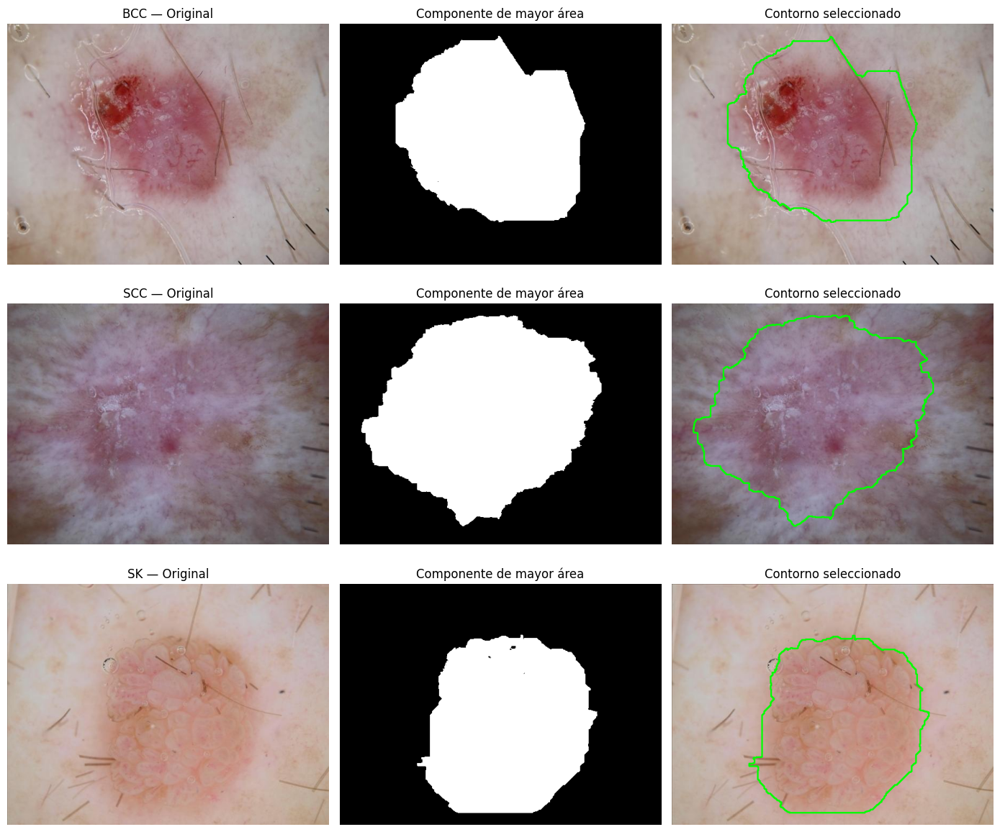

In [37]:
mascaras_limpias = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_grabcut[tipo]

    # Identificar las regiones blancas conectadas
    cantidad, etiquetas, estadisticas, _ = (
        cv2.connectedComponentsWithStats(mascara, connectivity=8)
    )

    limpia = np.zeros_like(mascara)

    if cantidad > 1:
        # La etiqueta 0 es el fondo
        mayor = 1 + np.argmax(
            estadisticas[1:, cv2.CC_STAT_AREA]
        )
        limpia[etiquetas == mayor] = 255

    mascaras_limpias[tipo] = limpia

    # Dibujar solamente el contorno de la región seleccionada
    contornos, _ = cv2.findContours(
        limpia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    resultado = original.copy()
    cv2.drawContours(resultado, contornos, -1, (0, 255, 0), 2)

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        limpia, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Componente de mayor área")

    axes[fila, 2].imshow(resultado)
    axes[fila, 2].set_title("Contorno seleccionado")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:
%matplotlib inline